# v4: new font (2026-10-31), relabel 100k automatically, train from v3's weights

On 2026-10-31 the captcha changed again: same 150x45 size, 5 characters, red letters and alphabet, but a bolder font
and large soft gray blobs drawn over the letters. The model reads **three levels** (`prep.clean`, same as the
extension's `model.js clean()`): letters 0, gray blobs 128, paper 255. With letters only (`prep.ink`, v1 to the first
v4) a blob leaves a hole the model can't tell from a missing stroke; keeping the blobs gained ~1.5 points on gold.
Older two-level models (the teacher v3) still read through `prep.ink`'s view: `load_model` picks it from the checkpoint. The worst one: the
new **J** has no top bar and every old model reads it as **3** (v3 outputs J for 0.1% of characters instead of ~2.7%).

1. **Gold**: 200 random captchas, pre-labeled by v3; you check them (section 4). Test set only, never trained on.
   v3 reads every J as 3, so expect to correct those.
2. **Relabel** (automatic): v3 (`../models/captcha_cnn_v3.pt`) reads every captcha. Training labels:
   **agree** (v3 == Apple Vision) and **vision_fix** (they differ only where v3 says 3 and Vision says J: Vision is
   right there). Other disagreements go to your review queue.
3. **Train** a baseline on those labels, starting from v3's weights. **Test** on gold.
4. **Review** 50 at a time (disagreements first), **fine-tune**, repeat 4 until gold stops improving. Then a v5 round
   relabels with v4's best (it reads J itself) to recover the captchas v3 and Vision both misread.

Before section 4: the captchas in `../data/captchas.zip` (`<id>.png`, any folder inside, e.g.
`zip -0 -q -r data/captchas.zip "<folder>"`), then `python3 scripts/label_vision.py` from the project root
(~10 min). The ids are new: nothing from `../archive/v2_2026-10-31/` (old gold, labels, reviews) applies here.


## 1. Setup and paths

In [1]:
import csv, json, math, os, random, sys, time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

sys.path.insert(0, "../scripts")
import prep   # clean(): three-level image the CNN reads; ink(): letters only, for Vision and two-level models

# images: ../data/captchas.zip (the 2026-10-31 font), read with prep.open_captcha(id); no loose PNGs
GOLD_CSV = "../data/gold.csv"                # 200 test captchas, never trained on or reviewed (audit_gold.py)
REVIEWS = "../data/reviews.json"             # your typed answers (review.py adds to it)
VISION_LABELS = "../data/labels_vision.csv"  # Apple Vision's read of every captcha (scripts/label_vision.py)
TEACHER = "../models/captcha_cnn_v3.pt"      # best previous model on the new font (reads J as 3): pre-labels gold, relabels all
LABELS_CSV = "../data/labels_v4.csv"         # written by the relabel cell
CACHE = "../cache/clean_images.npz"          # prep.clean images, so re-runs skip reading 100k PNGs (keyed by zip size + time)
MODEL_PATH = "../models/captcha_cnn_v4.pt"   # the new baseline
FT_PATH = "../models/captcha_cnn_v4_ft.pt"   # the new baseline fine-tuned on your reviews
os.makedirs("../models", exist_ok=True)
os.makedirs("../cache", exist_ok=True)

SEED = 0
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

_teacher = torch.load(TEACHER, map_location="cpu")
ALPHABET, LENGTH = _teacher["alphabet"], _teacher["length"]   # same classes as v1-v3 and the extension
assert (ALPHABET, LENGTH) == (prep.ALPHABET, prep.LENGTH)
CHAR_TO_IDX = {c: i for i, c in enumerate(ALPHABET)}
print("device:", DEVICE, "| alphabet:", ALPHABET)

device: mps | alphabet: 2345689ABDEFGHJLMNQRTYabdefghijmnqrty


## 2. Load all images (three levels: letters, blobs, paper; cached after the first run, ~1–2 min), Vision reads and gold

In [2]:
ALL_IDS = np.array(prep.captcha_ids())
_zip_stat = os.stat(prep.IMAGES_ZIP)
SOURCE = np.array([_zip_stat.st_size, _zip_stat.st_mtime_ns])   # a re-zipped or different captcha set rebuilds the cache

cached = np.load(CACHE) if os.path.exists(CACHE) else None
if (cached is not None and "source" in cached and np.array_equal(cached["source"], SOURCE)
        and np.array_equal(cached["ids"], ALL_IDS)):
    imgs = cached["imgs"]
else:
    t = time.time()
    with ThreadPoolExecutor(8) as ex:
        imgs = np.stack(list(ex.map(lambda i: prep.clean(prep.open_captcha(i)), ALL_IDS)))
    np.savez(CACHE, ids=ALL_IDS, imgs=imgs, source=SOURCE)
    print(f"read {len(imgs)} images in {time.time() - t:.0f}s")
H, W = imgs.shape[1:]
X = torch.from_numpy(imgs).to(DEVICE)   # uint8, all images on the GPU (~0.7 GB)
row_of = {i: k for k, i in enumerate(ALL_IDS)}

VISION = {}   # id -> Vision's read, "" where it gave no valid 5-character answer
if os.path.exists(VISION_LABELS):
    with open(VISION_LABELS) as f:
        VISION = {r["id"]: r["vision"] for r in csv.DictReader(f)}
GOLD = {}     # id -> {label, model, vision, checked}; filled by audit_gold.py
if os.path.exists(GOLD_CSV):
    with open(GOLD_CSV) as f:
        GOLD = {r["id"]: r for r in csv.DictReader(f)}
print("images:", imgs.shape, f"| Vision reads: {len(VISION)}/{len(ALL_IDS)}",
      f"| gold: {len(GOLD)} ({sum(bool(g['checked']) for g in GOLD.values())} checked)")

read 100000 images in 18s
images: (100000, 45, 150) | Vision reads: 100000/100000 | gold: 200 (200 checked)


## 3. Model definition and helpers (same network as v1)

In [3]:
class CaptchaCNN(nn.Module):
    levels = 3   # input cleaning: 3 = prep.clean; load_model sets 2 for checkpoints trained on prep.ink

    def __init__(self, n_classes, length=LENGTH, widths=(32, 64, 128, 192), dropout=0.3):
        super().__init__()
        layers, c_in = [], 1
        for c in widths:   # each block halves H and W: 45x150 -> 2x9
            layers += [
                nn.Conv2d(c_in, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True),
                nn.Conv2d(c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            ]
            c_in = c
        self.features = nn.Sequential(*layers)
        n_cols = W // 2 ** len(widths)   # 9 columns left, kept apart so heads know left from right
        self.shared = nn.Sequential(nn.Flatten(), nn.Dropout(dropout),
                                    nn.Linear(c_in * n_cols, 512), nn.ReLU(inplace=True), nn.Dropout(dropout))
        self.heads = nn.ModuleList(nn.Linear(512, n_classes) for _ in range(length))

    def forward(self, x):
        z = self.features(x).mean(dim=2)   # average over height -> (B, C, columns)
        z = self.shared(z)
        return torch.stack([head(z) for head in self.heads], dim=1)   # (B, LENGTH, n_classes)

def to_input(x, levels=3):
    """uint8 (B, H, W) from prep.clean -> float (B, 1, H, W): letters 1, blobs ~0.5, paper 0.
    levels=2: blobs become paper, i.e. prep.ink, what the two-level models (up to the first v4) were trained on."""
    if levels == 2:
        x = torch.where(x == 0, 0, 255)
    return (1 - x.float() / 255).unsqueeze(1)

def load_model(path):
    ckpt = torch.load(path, map_location=DEVICE)
    m = CaptchaCNN(len(ckpt["alphabet"]), ckpt["length"], ckpt["widths"], ckpt["config"]["dropout"]).to(DEVICE)
    m.load_state_dict(ckpt["state_dict"])
    m.levels = ckpt.get("levels", 2)   # checkpoints without it were trained on prep.ink
    return m.eval(), ckpt

@torch.no_grad()
def model_reads(m, ids, batch_size=2048, desc="model reads"):
    """Model reads + weakest-character confidence for a list of image ids."""
    m.eval()
    reads, confs = [], []
    for k in tqdm(range(0, len(ids), batch_size), desc=desc, leave=False):
        x = to_input(X[torch.tensor([row_of[i] for i in ids[k:k + batch_size]]).to(DEVICE)], m.levels)
        conf, idx = m(x).softmax(-1).max(-1)
        reads += ["".join(ALPHABET[j] for j in p) for p in idx.cpu().tolist()]
        confs += conf.min(-1).values.cpu().tolist()
    return reads, confs

print(f"{sum(p.numel() for p in CaptchaCNN(len(ALPHABET)).parameters()) / 1e6:.2f}M parameters")

def show(i):
    """The original captcha, big enough to read (reviews and gold checks)."""
    plt.figure(figsize=(7, 2.1))
    plt.imshow(prep.open_captcha(i).convert("RGB"))
    plt.axis("off")
    plt.show()

1.82M parameters


## 4. Gold: build + pre-label 200 test captchas (first run), then check them
Enter = label right, type the truth if not, s = skip, q = stop. Re-run any time to continue; `q` right away just builds.
Gold scores stay provisional until all 200 are checked (pre-labels come from the teacher, so they flatter it).
v3 reads every J as 3: look for J wherever the pre-label has a 3.

In [4]:
%run -i ../scripts/audit_gold.py

200/200 gold checked, 0 to go
200/200 gold checked


## 5. Relabel every captcha with the teacher; agree with Vision (or Vision's J for the teacher's 3) = training label (~30 s)

In [5]:
%run -i ../scripts/relabel.py

model reads:   0%|          | 0/49 [00:00<?, ?it/s]

model reads:   2%|▏         | 1/49 [00:01<00:56,  1.18s/it]

model reads:   4%|▍         | 2/49 [00:01<00:39,  1.18it/s]

model reads:   6%|▌         | 3/49 [00:02<00:33,  1.38it/s]

model reads:   8%|▊         | 4/49 [00:02<00:30,  1.49it/s]

model reads:  10%|█         | 5/49 [00:03<00:28,  1.57it/s]

... (41 outputs left out)

model reads:  96%|█████████▌| 47/49 [00:28<00:01,  1.68it/s]

model reads:  98%|█████████▊| 48/49 [00:28<00:00,  1.69it/s]

model reads: 100%|██████████| 49/49 [00:29<00:00,  1.81it/s]

wrote ../data/labels_v4.csv: 52970 agree with Vision, 4493 Vision fixes [('3', 'J')], 42337 disagree, 0 your reviews; gold's 200 left out (the notebook's splits cell picks what trains)
  disagreeing characters (teacher -> Vision): [(('y', 'Y'), 2692), (('B', '8'), 2173), (('8', '5'), 1786), (('3', 'J'), 1780), (('g', '9'), 1295), (('6', 'G'), 1235), (('8', 'B'), 1192), (('j', 'i'), 1094), (('q', 'Q'), 1040), (('f', 'F'), 989), (('q', 'g'), 923), (('9', 'g'), 908)]
  of the disagreements, Vision gave no valid read on 13001
  teacher confidence < 0.3:   4569 images (4.6%)
  teacher confidence < 0.5:  19080 images (19.1%)
  teacher confidence < 0.7:  40583 images (40.7%)


## 6. Labels and splits
**agree** and **vision_fix** labels split 70/20/10 into train / test / val; your reviews all go to train; **disagree**
is not used; gold stays apart. Val and test measure agreement with teacher + Vision, so they read high: only **gold**
is the real score.

In [6]:
with open(LABELS_CSV) as f:
    rows = list(csv.DictReader(f))
assert not any(r["id"] in GOLD for r in rows), "a gold captcha is in the training labels"
auto = [r for r in rows if r["source"] in ("agree", "vision_fix")]
reviewed = [r for r in rows if r["source"] == "review"]
random.Random(SEED).shuffle(auto)
n_train, n_test = int(0.7 * len(auto)), int(0.2 * len(auto))

def gold_rows():
    """Gold rows the model can be scored on (labels within its alphabet)."""
    return [{"id": i, "label": g["label"]} for i, g in GOLD.items() if set(g["label"]) <= set(ALPHABET)]

split_rows = {
    "train": auto[:n_train] + reviewed,
    "test": auto[n_train:n_train + n_test],
    "val": auto[n_train + n_test:],
    "gold": gold_rows(),
}

def encode(label):
    return [CHAR_TO_IDX[c] for c in label]

def decode_pred(p):
    return "".join(ALPHABET[i] for i in p)

data = {name: (torch.tensor([row_of[r["id"]] for r in rs]), torch.tensor([encode(r["label"]) for r in rs]))
        for name, rs in split_rows.items()}
print({k: len(v) for k, v in split_rows.items()}, f"(train includes {len(reviewed)} reviews)")
if len(split_rows["gold"]) < len(GOLD):
    print(f"{len(GOLD) - len(split_rows['gold'])} gold captchas use characters outside the alphabet: not scored")

{'train': 40224, 'test': 11492, 'val': 5747, 'gold': 200} (train includes 0 reviews)


## 7. Batching and augmentation (preview: originals on top, augmented below)

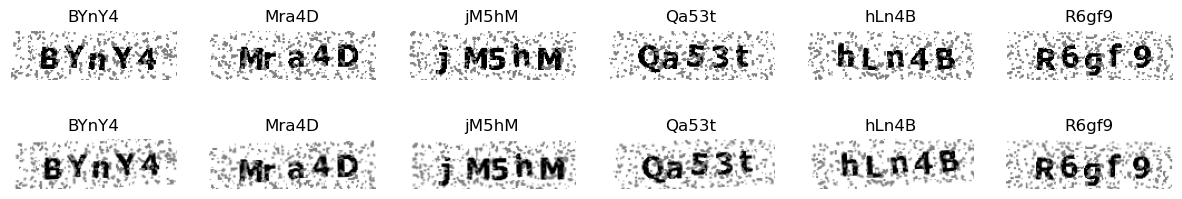

In [7]:
def batches(split, batch_size, shuffle, levels=3):
    idx, y = data[split]
    order = torch.randperm(len(idx)) if shuffle else torch.arange(len(idx))
    for k in range(0, len(idx), batch_size):
        j = order[k:k + batch_size]
        yield to_input(X[idx[j].to(DEVICE)], levels), y[j].to(DEVICE)

def augment(x, max_shift=4, max_rot=4):
    """Random shift (px) and rotation (degrees) per image, whole batch at once on the GPU.
    No flips: a mirrored letter is a different letter."""
    b, _, h, w = x.shape
    rnd = lambda: torch.rand(b, device=x.device) * 2 - 1
    ang = rnd() * max_rot * math.pi / 180
    cos, sin = torch.cos(ang), torch.sin(ang)
    tx, ty = rnd() * max_shift * 2 / w, rnd() * max_shift * 2 / h
    theta = torch.stack([torch.stack([cos, -sin * h / w, tx], 1),
                         torch.stack([sin * w / h, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, padding_mode="zeros", align_corners=False)

x, y = next(batches("train", 6, shuffle=True))
fig, ax = plt.subplots(2, 6, figsize=(15, 2.6))
for k, img in enumerate(torch.cat([x, augment(x)]).cpu()):
    ax[k // 6, k % 6].imshow(img[0], cmap="gray_r", vmin=0, vmax=1)
    ax[k // 6, k % 6].set_title(decode_pred(y[k % 6].tolist()))
    ax[k // 6, k % 6].axis("off")
plt.show()

## 8. Training and evaluation functions

In [8]:
@torch.no_grad()
def predict(model, split, batch_size=1024):
    model.eval()
    return torch.cat([model(x).argmax(-1).cpu() for x, _ in batches(split, batch_size, False, model.levels)])

def evaluate(model, split):
    p, y = predict(model, split), data[split][1]
    return {"exact": (p == y).all(1).float().mean().item(), "char": (p == y).float().mean().item()}

def train(cfg, tag=""):
    """Trains with cfg; keeps the epoch with the best val exact-match. Returns (model, best val)."""
    torch.manual_seed(cfg["seed"])
    model = CaptchaCNN(len(ALPHABET), dropout=cfg["dropout"]).to(DEVICE)
    if cfg["init"]:   # start from a trained model's weights instead of random ones
        model.load_state_dict(torch.load(cfg["init"], map_location=DEVICE)["state_dict"])
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    steps_per_epoch = math.ceil(len(data["train"][0]) / cfg["batch"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], total_steps=cfg["epochs"] * steps_per_epoch)
    best, best_state, stale = -1.0, None, 0
    for epoch in range(1, cfg["epochs"] + 1):
        model.train()
        t, total = time.time(), torch.zeros((), device=DEVICE)
        bar = tqdm(batches("train", cfg["batch"], shuffle=True), total=steps_per_epoch,
                   desc=f"{tag}epoch {epoch}/{cfg['epochs']}", leave=False)
        for step, (x, y) in enumerate(bar, 1):
            if cfg["augment"]:
                x = augment(x)
            loss = F.cross_entropy(model(x).flatten(0, 1), y.flatten(), label_smoothing=cfg["smoothing"])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
            total += loss.detach()
            if step % 50 == 0:   # reading the loss forces a GPU sync, so only now and then
                bar.set_postfix(loss=f"{total.item() / step:.3f}")
        val = evaluate(model, "val")
        gold_r = evaluate(model, "gold")
        print(f"{tag}epoch {epoch:>2}/{cfg['epochs']}  loss {total.item() / steps_per_epoch:.3f}  "
              f"val exact {val['exact']:.2%}  char {val['char']:.2%}  "
              f"gold exact {gold_r['exact']:.2%}  {time.time() - t:.0f}s", flush=True)
        if val["exact"] > best:
            best, stale = val["exact"], 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= cfg["patience"]:
                print(f"{tag}stopping early, no val gain for {stale} epochs")
                break
    model.load_state_dict(best_state)
    return model, best

# from v3's weights (same alphabet and layout, so it adapts fast). From scratch: init=None, epochs=10, lr=2e-3, patience=4
CFG = dict(init=TEACHER, epochs=6, batch=256, lr=5e-4, weight_decay=1e-4, dropout=0.3,
           smoothing=0.1, augment=True, patience=3, seed=SEED)

## 9. Train the baseline from v3's weights (~5 min)

In [9]:
model, best_val = train(CFG)
print(f"best val exact: {best_val:.2%}")

epoch 1/6:   0%|          | 0/158 [00:00<?, ?it/s]

epoch 1/6:   1%|          | 1/158 [00:00<00:41,  3.77it/s]

epoch 1/6:   1%|▏         | 2/158 [00:00<00:28,  5.52it/s]

epoch 1/6:   2%|▏         | 3/158 [00:00<00:32,  4.71it/s]

epoch 1/6:   3%|▎         | 4/158 [00:00<00:35,  4.37it/s]

epoch 1/6:   3%|▎         | 5/158 [00:01<00:36,  4.19it/s]

... (946 outputs left out)

epoch 6/6:  99%|█████████▉| 157/158 [00:39<00:00,  4.00it/s, loss=0.748]

epoch 6/6: 100%|██████████| 158/158 [00:40<00:00,  3.96it/s, loss=0.748]

epoch  6/6  loss 0.748  val exact 96.50%  char 99.28%  gold exact 96.50%  42s


best val exact: 96.55%


## 10. Test on gold: teacher (v3, never saw the new font) vs the new baseline

val   (  5747 images)  exact 96.55%  char 99.29%


test  ( 11492 images)  exact 96.82%  char 99.35%
gold  (   200 images)  exact 97.00%  char 99.30%
gold, teacher (v3): 86.00%


gold, v4 baseline: 97.00%
per-position accuracy on gold: ['99.5%', '99.5%', '99.5%', '99.0%', '99.0%']
confusions on gold (true -> predicted): [(('6', '5'), 4), (('y', 'Y'), 2), (('J', '3'), 1)]


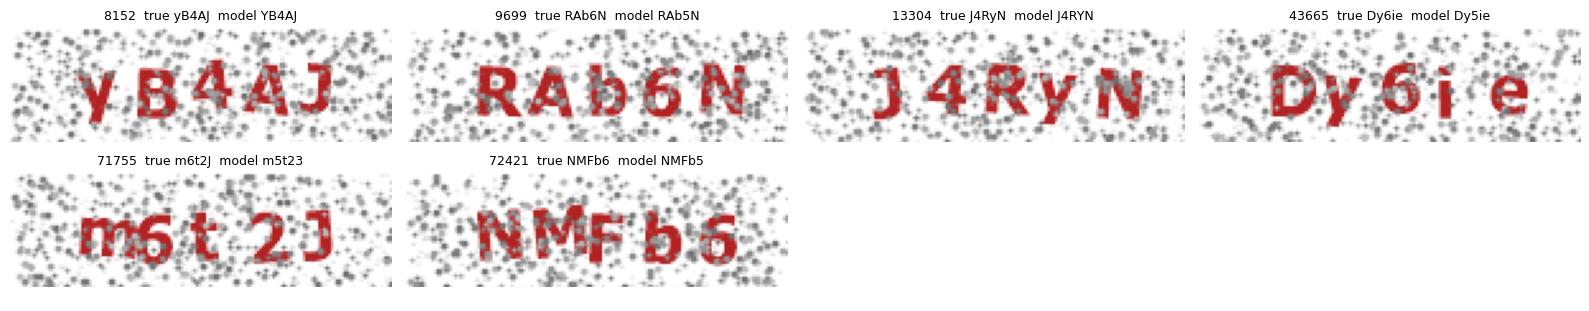

In [10]:
for split in ("val", "test", "gold"):
    r = evaluate(model, split)
    print(f"{split:<5} ({len(data[split][0]):>6} images)  exact {r['exact']:.2%}  char {r['char']:.2%}")

n_checked = sum(bool(g["checked"]) for g in GOLD.values())
if n_checked < len(GOLD):
    print(f"only {n_checked}/{len(GOLD)} gold checked: scores are provisional and flatter the teacher")
teacher, _ = load_model(TEACHER)
for name, m in (("teacher (v3)", teacher), ("v4 baseline", model)):
    print(f"gold, {name}: {evaluate(m, 'gold')['exact']:.2%}")

p_gold, y_gold = predict(model, "gold"), data["gold"][1]
print("per-position accuracy on gold:", [f"{a:.1%}" for a in (p_gold == y_gold).float().mean(0).tolist()])
mix = Counter((ALPHABET[t], ALPHABET[q]) for pp, yy in zip(p_gold, y_gold)
              for t, q in zip(yy.tolist(), pp.tolist()) if t != q)
print("confusions on gold (true -> predicted):", mix.most_common(10))

gold_list = split_rows["gold"]
wrong = [k for k in range(len(gold_list)) if not torch.equal(p_gold[k], y_gold[k])]
cols, rows_n = 4, max(1, math.ceil(len(wrong) / 4))
fig, ax = plt.subplots(rows_n, cols, figsize=(16, 1.6 * rows_n), squeeze=False)
for a in ax.flat:
    a.axis("off")
for a, k in zip(ax.flat, wrong):
    a.imshow(prep.open_captcha(gold_list[k]["id"]).convert("RGB"))
    a.set_title(f"{gold_list[k]['id']}  true {gold_list[k]['label']}  model {decode_pred(p_gold[k].tolist())}", fontsize=9)
plt.tight_layout()
plt.show()

## 10b. Correct gold labels by id
Put `id: label` pairs (exact case) in `GOLD_FIXES`, run, then re-run section 10. Section 10's figure shows each
miss's id with the gold label and the model's read; fix the gold only where the gold label itself is wrong.


In [11]:
GOLD_FIXES = {   # gold id -> correct label, e.g. "9699": "RAb6N"
}
%run -i ../scripts/audit_gold.py

200/200 gold checked, 0 to go
200/200 gold checked
gold split refreshed: re-run the test cell to see the new scores


## 11. Save, reload, check the reload predicts the same

In [12]:
torch.save({
    "state_dict": model.state_dict(),
    "alphabet": ALPHABET,
    "length": LENGTH,
    "image_size": (H, W),
    "widths": (32, 64, 128, 192),
    "levels": 3,
    "preprocess": "prep.clean: letters (r - g > 60 and r - b > 60) 0, blobs (r + g + b < 600) 128, rest 255",
    "config": CFG,
    "trained_on": LABELS_CSV,
    "input": "grayscale HxW, x = 1 - pixel/255 (letters 1, blobs ~0.5, paper 0), shape (B, 1, H, W)",
    "scores": {s: evaluate(model, s) for s in ("val", "test", "gold")},
}, MODEL_PATH)

reloaded, ckpt = load_model(MODEL_PATH)
assert torch.equal(predict(reloaded, "gold"), predict(model, "gold")), "reloaded model predicts differently"
print(f"saved {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB), reload OK:", ckpt["scores"])

saved ../models/captcha_cnn_v4.pt (7.3 MB), reload OK: {'val': {'exact': 0.9655472636222839, 'char': 0.9929354190826416}, 'test': {'exact': 0.9682387709617615, 'char': 0.993508517742157}, 'gold': {'exact': 0.9700000286102295, 'char': 0.9929999709129333}}


## 12. Review 50 at a time: disagreements with Vision first, then the least confident reads
Enter = right, type the truth if wrong, s = skip, q = quit. Settings (N_REVIEW, FOCUS, POOL) at the top of
`../scripts/review.py`. Reviews go to `../data/reviews.json` (new for this font). After each batch, run 13 (and 14) to fine-tune.

In [ ]:
%run -i ../scripts/review.py

## 13. Fine-tune the baseline on all reviews → `../models/captcha_cnn_v4_ft.pt` (re-run after each review batch)

In [ ]:
%run -i ../scripts/finetune.py

## 14. What the fine-tune fixed and broke on gold (vs the baseline)

In [ ]:
base_model, _ = load_model(MODEL_PATH)
p_base, p_ft, y = predict(base_model, "gold"), predict(ft_model, "gold"), data["gold"][1]
for k, r in enumerate(split_rows["gold"]):
    b, f = torch.equal(p_base[k], y[k]), torch.equal(p_ft[k], y[k])
    if b != f:
        print(f"{'FIXED ' if f else 'BROKEN'} {r['id']}  true {r['label']}  "
              f"baseline {decode_pred(p_base[k].tolist())}  fine-tuned {decode_pred(p_ft[k].tolist())}")